# Linear regression from conditional expectation
## Palmer Penguins: flipper length and body mass

We observe pairs

$$
(X_i,Y_i)
=
(\text{flipper length},\text{body mass}).
$$

The central prediction question is

$$
\boxed{\text{Given }X=x,\text{ what should we predict for }Y?}
$$

Under squared-error loss, the optimal population predictor is

$$
\boxed{m(x)=\mathbb E[Y\mid X=x].}
$$

Linear regression assumes

$$
\boxed{m(x)=\beta_0+\beta_1x.}
$$

Then

$$
Y=\beta_0+\beta_1X+\varepsilon,
\qquad
\mathbb E[\varepsilon\mid X]=0.
$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams["figure.figsize"]=(7,4.8)
rng=np.random.default_rng(10)

penguins=pd.read_csv("palmer_penguins.csv")
penguins=penguins.dropna(subset=["flipper_length_mm","body_mass_g"]).copy()

x=penguins["flipper_length_mm"].to_numpy()
y=penguins["body_mass_g"].to_numpy()

print(f"n = {len(x)}")
penguins[["species","flipper_length_mm","body_mass_g"]].head()

n = 342


,species,flipper_length_mm,body_mass_g
0,Adelie,181.0,3750.0
1,Adelie,186.0,3800.0
2,Adelie,195.0,3250.0
4,Adelie,193.0,3450.0
5,Adelie,190.0,3650.0


## 1. Ignore \(X\): one prediction for everyone

If we predict everyone using one constant \(c\), then under squared-error loss the best constant is

$$
c=\mathbb E[Y].
$$

From data,

$$
\hat y=\bar y.
$$

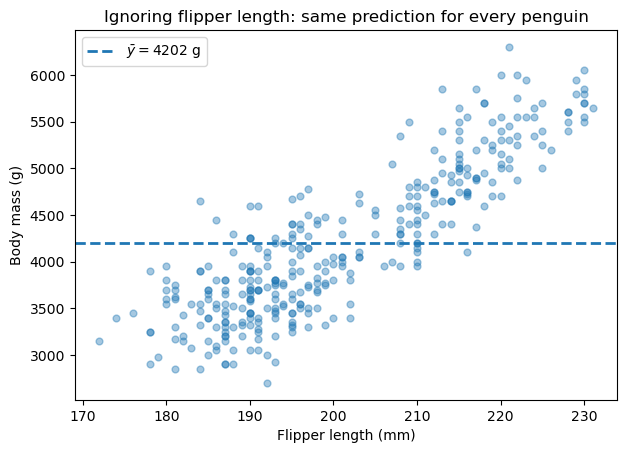

In [2]:
ybar=y.mean()

plt.scatter(x,y,alpha=0.4,s=24)
plt.axhline(ybar,linestyle="--",linewidth=2,label=rf"$\bar y={ybar:.0f}$ g")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("Ignoring flipper length: same prediction for every penguin")
plt.legend()
plt.show()

### Question

Should a penguin with a 175 mm flipper and one with a 225 mm flipper receive the same predicted body mass?

If not, then we need a prediction that depends on \(x\).

## 2. Why conditional expectation?

Let \(g(X)\) be any predictor and define

$$
m(X)=\mathbb E[Y\mid X].
$$

Then

$$
Y-g(X)
=
(Y-m(X))+(m(X)-g(X)).
$$

Squaring,

$$
(Y-g(X))^2
=
(Y-m(X))^2
+(m(X)-g(X))^2
+2(Y-m(X))(m(X)-g(X)).
$$

After taking expectations, the cross term vanishes because

$$
\mathbb E[Y-m(X)\mid X]=0.
$$

Therefore,

$$
\boxed{
\mathbb E[(Y-g(X))^2]
=
\mathbb E[(Y-m(X))^2]
+
\mathbb E[(m(X)-g(X))^2].
}
$$

Hence the optimal squared-error predictor is

$$
\boxed{
g^*(X)=\mathbb E[Y\mid X].
}
$$

## 3. Empirical glimpse of $\mathbb E[Y\mid X=x]$

We cannot observe the population conditional mean directly.

As a rough visualization, group nearby flipper lengths and compute the average body mass in each group.

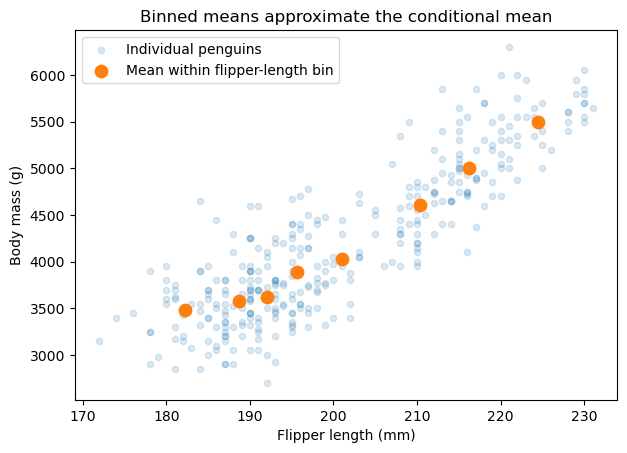

,x_mean,y_mean,n
0,182.229167,3483.854167,48
1,188.686275,3576.960784,51
2,192.057143,3618.571429,35
3,195.595238,3893.452381,42
4,201.076923,4026.923077,39
5,210.309524,4609.523810,42
6,216.166667,5004.761905,42
7,224.465116,5495.930233,43


In [3]:
tmp=penguins[["flipper_length_mm","body_mass_g"]].copy()
tmp["bin"]=pd.qcut(tmp["flipper_length_mm"],q=8,duplicates="drop")

binned=(tmp.groupby("bin",observed=True)
          .agg(x_mean=("flipper_length_mm","mean"),
               y_mean=("body_mass_g","mean"),
               n=("body_mass_g","size"))
          .reset_index())

plt.scatter(x,y,alpha=0.16,s=20,label="Individual penguins")
plt.scatter(binned["x_mean"],binned["y_mean"],s=80,label="Mean within flipper-length bin")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("Binned means approximate the conditional mean")
plt.legend()
plt.show()

binned[["x_mean","y_mean","n"]]

The conditional mean appears to increase with \(x\).

Rather than estimate an unrelated mean for every possible \(x\), impose the simplest smooth structure:

$$
\boxed{
\mathbb E[Y\mid X=x]=\beta_0+\beta_1x.
}
$$

## 4. Where does the noise term come from?

Define

$$
\varepsilon
=
Y-\mathbb E[Y\mid X].
$$

Then

$$
Y=\mathbb E[Y\mid X]+\varepsilon.
$$

Under the linear conditional-mean model,

$$
\boxed{
Y=\beta_0+\beta_1X+\varepsilon.
}
$$

By construction,

$$
\boxed{
\mathbb E[\varepsilon\mid X]=0.
}
$$

The noise term is not necessarily measurement error. It is whatever variation remains after using the information in \(X\).

## 5. Estimate the line

Least squares chooses

$$
(\hat\beta_0,\hat\beta_1)
=
\arg\min_{\beta_0,\beta_1}
\sum_i(y_i-\beta_0-\beta_1x_i)^2.
$$

The solution is

$$
\hat\beta_1
=
\frac{\sum_i(x_i-\bar x)(y_i-\bar y)}
{\sum_i(x_i-\bar x)^2},
\qquad
\hat\beta_0=\bar y-\hat\beta_1\bar x.
$$

In [4]:
xbar=x.mean()
ybar=y.mean()

beta1=np.sum((x-xbar)*(y-ybar))/np.sum((x-xbar)**2)
beta0=ybar-beta1*xbar

print(f"beta0_hat = {beta0:.2f} g")
print(f"beta1_hat = {beta1:.2f} g/mm")

beta0_hat = -5780.83 g
beta1_hat = 49.69 g/mm


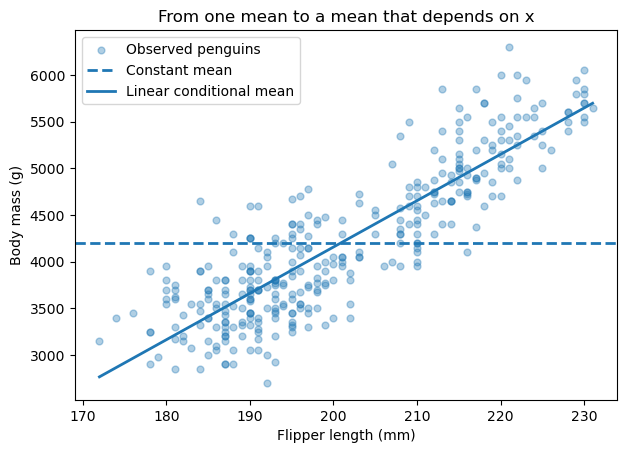

In [5]:
xx=np.linspace(x.min(),x.max(),200)
yy=beta0+beta1*xx

plt.scatter(x,y,alpha=0.35,s=24,label="Observed penguins")
plt.axhline(ybar,linestyle="--",linewidth=2,label="Constant mean")
plt.plot(xx,yy,linewidth=2,label="Linear conditional mean")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("From one mean to a mean that depends on x")
plt.legend()
plt.show()

## 6. Residuals: observed unexplained variation

The population error is

$$
\varepsilon_i=Y_i-\beta_0-\beta_1X_i.
$$

After fitting, we compute

$$
\boxed{
e_i=y_i-\hat\beta_0-\hat\beta_1x_i.
}
$$

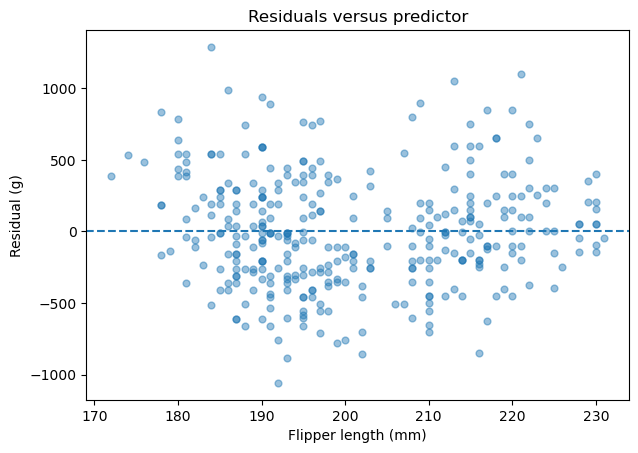

Mean residual = 0.0000000000 g


In [6]:
yhat=beta0+beta1*x
resid=y-yhat

plt.scatter(x,resid,alpha=0.45,s=24)
plt.axhline(0,linestyle="--",linewidth=1.5)
plt.xlabel("Flipper length (mm)")
plt.ylabel("Residual (g)")
plt.title("Residuals versus predictor")
plt.show()

print(f"Mean residual = {resid.mean():.10f} g")

A systematic pattern in residuals suggests that the linear conditional mean is missing structure.

## 7. Gaussian noise is an additional assumption

So far we assumed only

$$
\mathbb E[Y\mid X=x]=\beta_0+\beta_1x.
$$

A stronger probabilistic model is

$$
\varepsilon\mid X=x\sim\mathcal N(0,\sigma^2),
$$

equivalently,

$$
\boxed{
Y\mid X=x
\sim
\mathcal N(\beta_0+\beta_1x,\sigma^2).
}
$$

At each \(x\), imagine a vertical Gaussian centered on the regression line.

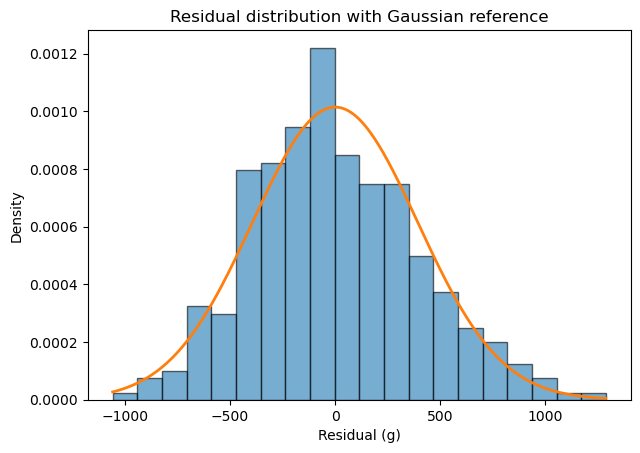

Gaussian-noise MLE sigma = 393.1 g


In [7]:
sigma=np.sqrt(np.mean(resid**2))

plt.hist(resid,bins=20,density=True,alpha=0.6,edgecolor="black")
grid=np.linspace(resid.min(),resid.max(),300)
plt.plot(grid,stats.norm.pdf(grid,0,sigma),linewidth=2)
plt.xlabel("Residual (g)")
plt.ylabel("Density")
plt.title("Residual distribution with Gaussian reference")
plt.show()

print(f"Gaussian-noise MLE sigma = {sigma:.1f} g")

## 8. Gaussian MLE gives least squares

If

$$
Y_i\mid X_i=x_i
\sim
\mathcal N(\beta_0+\beta_1x_i,\sigma^2),
$$

then

$$
\ell
=
-\frac n2\log(2\pi\sigma^2)
-
\frac{1}{2\sigma^2}
\sum_i(y_i-\beta_0-\beta_1x_i)^2.
$$

Therefore,

$$
\boxed{
\text{maximize Gaussian likelihood}
\iff
\text{minimize squared residuals}.
}
$$

## 9. Some apparent noise is structured

Color the same data by species.

In [ ]:
for species in penguins["species"].dropna().unique():
    d=penguins[penguins["species"]==species]
    plt.scatter(d["flipper_length_mm"],d["body_mass_g"],alpha=0.7,s=28,label=species)

plt.plot(xx,yy,linewidth=2,label="One regression line")
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("Some unexplained variation is associated with species")
plt.legend()
plt.show()

This gives a useful interpretation of noise:

\[
\boxed{
\text{some of }\varepsilon\text{ may be variation explained by variables omitted from the model.}
\]

That naturally motivates multiple regression later.